In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from argus.utils.PathManager import PathManager_RES_Folder_UPOD

warnings.filterwarnings("ignore")

%load_ext autoreload
%autoreload 2

In [2]:
path_manager = PathManager_RES_Folder_UPOD()
filename = "logging.parquet"
path_log = path_manager.get_file_path("ARGUS25", "Silent_trial_data", filename)

df_log = pd.read_parquet(path_log)

In [3]:
df_log["date_created"] = df_log["created_at"].dt.date
df_log.groupby("date_created")["run_id"].nunique()

date_created
2025-12-17    16
2025-12-22     2
2025-12-24     4
2025-12-29     2
2026-01-03     2
2026-01-05     5
2026-01-08     2
2026-01-13     2
2026-01-18     1
2026-01-23     1
2026-01-28     1
2026-02-02     1
2026-02-07     1
2026-02-12     1
2026-02-17     1
2026-02-22     1
2026-02-27     1
2026-03-04     1
2026-03-09     1
2026-03-14     1
2026-03-19     1
2026-03-24     1
2026-03-29     1
2026-04-03     1
2026-04-08     1
2026-04-13     1
2026-04-18     1
2026-04-23     1
2026-04-28     1
2026-04-30     1
2026-05-05     1
2026-05-10     1
2026-05-11     3
2026-05-16     1
2026-05-21     1
2026-05-26     1
2026-05-31     1
2026-06-05     1
2026-06-10     1
2026-06-15     1
Name: run_id, dtype: int64

In [4]:
df_log.iloc[-1]["message"]

'Starting inference starting from: 2025-12-16 00:00:00'

In [5]:
trial_duration = df_log["created_at"].max() - df_log["created_at"].min()
print(trial_duration)

180 days 03:04:19.683000


Trial duration = time between first and last log: 180 days 03:04:19.683000

Note that the first run which is stored in our logging starts with patients from 2025-12-16. The first few runs are not stored in the logging. The prediction dataset also include patients with an index_dt between april and december 2025.

### Drop duplicate runs

The first cycles had duplicate entries which affected the processing times in those logs. All logs with duplicate entries were therefore excluded. This means all logs up until jan 13th. Also, the log from the fix on may 11th had duplicates due to multiple testing on the same day. These were also excluded

In [6]:
df_log["date_created"] = df_log["created_at"].dt.date

# dates that have more than one distinct run_id
bad_dates = df_log.groupby("date_created")["run_id"].nunique().loc[lambda x: x > 1].index

# keep only rows whose date is NOT in that bad list
df_log = df_log[~df_log["date_created"].isin(bad_dates)]

## Get number of patients during the preprocessing steps

In [7]:
df_patsel_analysis = df_log[["run_id", "created_at"]].drop_duplicates().reset_index(drop=True)


In [8]:
# Select errors:
error_flags = (
    df_log.groupby("run_id")["level"]
    .apply(lambda x: x.eq("ERROR").any())
    .reset_index()
    .rename(columns={"level": "error"})
)

df_patsel_analysis = df_patsel_analysis.merge(error_flags, on="run_id", how="left")
print(f"Number of runs: {df_patsel_analysis['run_id'].nunique()}")

Number of runs: 31


Total time to fix the error:

In [9]:
error_duration = df_patsel_analysis["created_at"].iloc[8] - df_patsel_analysis["created_at"].iloc[11]
print(error_duration)

11 days 22:48:29.803000


In [10]:
percentage = (error_duration / trial_duration) * 100

print(f"{percentage:.1f}%")

6.6%


In [11]:
extractions = {
    "initial_patsel": r"Initial number of rows in patient selection data:\s*(\d+)",
    "removed_age": r"Removing (\d+) rows due to Age out of range",
    "remaining_rows": r"Remaining rows:\s*(\d+)",
    "unique_patients": r"Number of unique patients remaining in the data:\s*(\d+)",
    "decursus_patients": r"Number of unique patients from patsel with decursus data: \s*(\d+)",
    "POB_noVG_patients": r"Number of unique patients with chest pain and no cardio history: \s*(\d+)",
    "Lab_patients": r"We have \s*(\d+) number of patients with lab data",
    "ECG_patients": r"After processing and dropping duplicates we have \s*(\d+) patients with ECG data",
    "BMI_patients": r"Processing pipeline completed for regular measurements: \s*(\d+) patients.",
    "BP_patients": r"Processing pipeline completed for blood_pressure measurements: \s*(\d+) patients.",
    "n_female": r"(\d+)\s+female",
    "n_male": r"(\d+)\s+male",
    "saved_patients": r"Patsel nr: \s*(\d+)",
}

for col, pattern in extractions.items():
    extracted = (
        df_log[["message", "run_id"]]
        .assign(**{col: df_log["message"].str.extract(pattern, expand=False)})
        .dropna(subset=[col])
        .assign(**{col: lambda d: d[col].astype("Int64")})[["run_id", col]]
        .groupby("run_id")[col]
        .max()
        .reset_index()
    )
    df_patsel_analysis = df_patsel_analysis.merge(extracted, on="run_id", how="left")


## Duplicate runs:

In [12]:
df_patsel_analysis.loc[df_patsel_analysis["created_at"].dt.date.duplicated(keep=False)]

,run_id,created_at,error,initial_patsel,removed_age,remaining_rows,unique_patients,decursus_patients,POB_noVG_patients,Lab_patients,ECG_patients,BMI_patients,BP_patients,n_female,n_male,saved_patients


We succesfully removed all duplicate runs

### Duplicates within the runs
Now it should be noted that the last day of a run is used for the first day of the next run. Therefore, there still is a number of duplicated patients in the log, but we cannot filter them out of the logging. Therefore, we will analyse the logging as it is and not use absolute, but percentece wise counts of data availability per run. The absolute counts will need to come from the original database. 

In [13]:
df_patsel_analysis = df_patsel_analysis.loc[~df_patsel_analysis["error"]]
print(f"Number of runs: {df_patsel_analysis['run_id'].nunique()}")

Number of runs: 28


In [14]:
print(df_patsel_analysis["initial_patsel"].sum())
# contain the <18years patients

2332


In [15]:
# pediatric patients removed - %
print(round(100 / df_patsel_analysis["initial_patsel"].sum() * (
    df_patsel_analysis["initial_patsel"].sum() - df_patsel_analysis["unique_patients"].sum()
),2))

2.7


In [16]:
# percentage with CAD related complaints
print(round(100 / df_patsel_analysis["initial_patsel"].sum() * df_patsel_analysis["POB_noVG_patients"].sum(),2))

30.32


In [17]:
df_patsel_analysis["removed_age"].sum()  # removed because <18years old

np.int64(60)

In [18]:
print(df_patsel_analysis["n_female"].sum())
print(df_patsel_analysis["n_male"].sum())
print(df_patsel_analysis["n_female"].sum() + df_patsel_analysis["n_male"].sum())
print(df_patsel_analysis["saved_patients"].sum())

317
390
707
707


## Latency analysis

In [19]:
df_log["created_at"] = pd.to_datetime(df_log["created_at"])
df_log["timestamp"] = pd.to_datetime(df_log["timestamp"])

# get total processing time:
total_time = (
    df_log.groupby("run_id")
    .apply(lambda g: (g["created_at"].max() - g["timestamp"].min()).total_seconds())
    .reset_index(name="total_time")
)

total_time

,run_id,total_time
0,07ecff18-af63-496f-8b62-62e56a78a6ad,65.826
1,0d2d9039-b022-47ad-b9f4-1ef454c60823,42.610
2,13e25474-568c-42d4-b922-612d428b736b,532.967
3,154412d6-2a18-4c8c-9784-31137a116f30,55.030
4,17c15efe-18d2-450d-8201-944f46d5b829,44.514
5,1ba6b470-11fa-4b42-afdd-5f58e5acbe1f,52.704
6,1f37a9fd-6317-4031-a47a-67a0f2f5053a,66.626
7,1fae9fa1-144b-47f8-90b3-9659c2f7c338,51.253
8,3d5fdca3-3c2d-43e6-bbe6-c197b43a9082,48.137
9,52329528-0cdc-4ca0-b661-508cfb85c622,74.950


In [20]:
df_patsel_analysis = df_patsel_analysis.merge(total_time, on="run_id", how="left")

In [21]:
(pd.set_option("display.max_columns", None),)

# get ETL_processing time:
ETL_time = (
    df_log.groupby("run_id")
    .apply(
        lambda g: (
            g["timestamp"].loc[g["message"] == "Successfully merged ECG with Patsel + Metingen + Lab"]
            - g["timestamp"].min()
        )
    )
    .reset_index(name="total_ETL_time")
    .assign(total_ETL_time=lambda d: d["total_ETL_time"].dt.total_seconds().round(2))
    .groupby("run_id")["total_ETL_time"]
    .min()  # min or max???
    .reset_index()
)

df_patsel_analysis = df_patsel_analysis.merge(ETL_time, on="run_id", how="left")

# extract block processing time from logging:
extractions = {
    "load_patsel_time": (r"load_patsel_data took (\d+\.\d+) seconds", None, None),
    "load_decursus_time": (r"load_decursus_data took (\d+\.\d+) seconds", None, None),
    "filter_pob_time": (r"filter_pob took (\d+\.\d+) seconds", None, None),
    "vg_filter_time": (r"vg_filter took (\d+\.\d+) seconds", None, None),
    "main_ETL_patsel_time": (r"main took (\d+\.\d+) seconds", "ETLPipeline_PatselProcessor", None),
    "load_lab_time": (r"load_lab_data took (\d+\.\d+) seconds", None, None),
    "process_lab_time": (r"process_lab took (\d+\.\d+) seconds", None, None),
    "process_ecg_time": (r"process_ecg took (\d+\.\d+) seconds", None, None),
    "process_meas_time": (r"process_measurements took (\d+\.\d+) seconds", None, None),
}

for col, (pattern, module_filter, line_filter) in extractions.items():
    df_source = df_log.copy()
    if module_filter:
        df_source = df_source[df_source["module"] == module_filter]
    if line_filter:
        df_source = df_source[df_source["line"] == line_filter]

    extracted = (
        df_source[["message", "run_id"]]
        .assign(**{col: df_source["message"].str.extract(pattern, expand=False)})
        .dropna(subset=[col])
        .assign(**{col: lambda d: d[col].astype(float).round(2)})[["run_id", col]]
        .groupby("run_id")[col]
        .last()
        .reset_index()
    )
    df_patsel_analysis = df_patsel_analysis.merge(extracted, on="run_id", how="left")


In [22]:
def extract_ecg_times(group):
    matches = group[group["message"].str.contains(r"load_ecg_data took", na=False)]
    times = (
        matches["message"].str.extract(r"load_ecg_data took (\d+\.\d+) seconds", expand=False).astype(float).round(2)
    )
    return pd.Series(
        {
            "load_ECG_classresults": times.iloc[0] if len(times) > 0 else None,
            "load_ECG_detail": times.iloc[1] if len(times) > 1 else None,
        }
    )


ecg_times = df_log.groupby("run_id").apply(extract_ecg_times).reset_index()

df_patsel_analysis = df_patsel_analysis.merge(ecg_times, on="run_id", how="left")

In [23]:
def extract_measurement_load_times(group):
    matches = (
        group["message"]
        .str.extract(r"load_measurement_data took (\d+\.\d+) seconds", expand=False)
        .dropna()
        .astype(float)
        .round(2)
    )
    return pd.Series(
        {
            "load_BMI_time": matches.iloc[0] if len(matches) > 0 else None,
            "load_BP_time": matches.iloc[1] if len(matches) > 1 else None,
        }
    )


measurement_load_times = pd.DataFrame(
    [
        {"run_id": run_id, **extract_measurement_load_times(group).to_dict()}
        for run_id, group in df_log.groupby("run_id")
    ]
)

df_patsel_analysis = df_patsel_analysis.merge(measurement_load_times, on="run_id", how="left")

In [24]:
def extract_preprocessor_main_times(group):
    matches = (
        group[group["module"] == "ETLPipeline_PreProcessor"]["message"]
        .str.extract(r"main took (\d+\.\d+) seconds", expand=False)
        .dropna()
        .astype(float)
        .round(2)
    )
    return pd.Series(
        {
            "main_measurements_ETL_time": matches.iloc[0] if len(matches) > 0 else None,
            "main_ECG_ETL_time": matches.iloc[1] if len(matches) > 1 else None,
            "main_Lab_ETL_time": matches.iloc[2] if len(matches) > 2 else None,
        }
    )


preprocessor_main_times = pd.DataFrame(
    [
        {"run_id": run_id, **extract_preprocessor_main_times(group).to_dict()}
        for run_id, group in df_log.groupby("run_id")
    ]
)

df_patsel_analysis = df_patsel_analysis.merge(preprocessor_main_times, on="run_id", how="left")


In [25]:
def extract_prediction_times(group):
    start_matches = group[group["message"].str.contains("Start prediction", na=False)]
    finish_female = group[
        group["message"].str.contains(r"Finished predictions for argus_calibrated_xgb_model_f\.pkl", na=False)
    ]
    finish_male = group[
        group["message"].str.contains(r"Finished predictions for argus_calibrated_xgb_model_m\.pkl", na=False)
    ]

    prediction_time_female = None
    prediction_time_male = None
    if len(start_matches) > 0 and len(finish_female) > 0:
        start_ts = pd.to_datetime(start_matches.iloc[1]["timestamp"])
        finish_ts = pd.to_datetime(finish_female.iloc[0]["timestamp"])
        prediction_time_female = round((finish_ts - start_ts).total_seconds(), 2)

    if len(start_matches) > 0 and len(finish_male) > 0:
        start_ts = pd.to_datetime(start_matches.iloc[0]["timestamp"])
        finish_ts = pd.to_datetime(finish_male.iloc[0]["timestamp"])
        prediction_time_male = round((finish_ts - start_ts).total_seconds(), 2)

    return pd.Series(
        {
            "prediction_time_female": prediction_time_female,
            "prediction_time_male": prediction_time_male,
        }
    )


prediction_times = pd.DataFrame(
    [{"run_id": run_id, **extract_prediction_times(group).to_dict()} for run_id, group in df_log.groupby("run_id")]
)

df_patsel_analysis = df_patsel_analysis.merge(prediction_times, on="run_id", how="left")

Between 23 januari and 7 februari the software latency was extremely high. This seems to be related to high demand on the network and data platform.

In [26]:
cols = [
    "total_time",
    "total_ETL_time",
    "main_ETL_patsel_time",
    "load_decursus_time",
    "filter_pob_time",
    "main_Lab_ETL_time",
    "main_ECG_ETL_time",
    "main_measurements_ETL_time",
]

for c in cols:
    print(c)
    latency_per_pat = df_patsel_analysis[c] / df_patsel_analysis["initial_patsel"]
    print(latency_per_pat.dropna().describe())
    print("\n")

print("prediction_time_female")
latency_per_pat = df_patsel_analysis["prediction_time_female"] / df_patsel_analysis["n_female"]
print(latency_per_pat.dropna().describe())
print("\n")

print("prediction_time_male")
latency_per_pat = df_patsel_analysis["prediction_time_male"] / df_patsel_analysis["n_male"]
print(latency_per_pat.dropna().describe())
print("\n")

total_time
count        28.0
mean     1.149612
std      1.172039
min      0.463563
25%       0.64923
50%      0.778756
75%      1.011094
max      5.174437
dtype: Float64


total_ETL_time
count        28.0
mean     1.141339
std      1.170571
min      0.459789
25%      0.634517
50%      0.772454
75%      0.995442
max       5.16233
dtype: Float64


main_ETL_patsel_time
count        28.0
mean     0.857153
std      1.169538
min      0.319507
25%      0.387247
50%      0.458947
75%      0.644029
max      4.903786
dtype: Float64


load_decursus_time
count        28.0
mean     0.301459
std      0.184056
min      0.099623
25%      0.185961
50%      0.226936
75%      0.321588
max      0.866214
dtype: Float64


filter_pob_time
count        28.0
mean     0.482296
std      1.043836
min      0.080423
25%      0.120305
50%      0.134763
75%      0.160018
max      3.946111
dtype: Float64


main_Lab_ETL_time
count        28.0
mean     0.065016
std      0.016948
min      0.030282
25%      0.054645
50%  

In [27]:
perc_prepros_total = 100 / df_patsel_analysis["total_time"] * df_patsel_analysis["total_ETL_time"]
perc_prepros_total.describe()

count    28.000000
mean     99.058215
std       0.763712
min      96.496815
25%      99.124088
50%      99.236691
75%      99.451857
max      99.766027
dtype: float64

The preprocessing modules together account for 99% of the total latency. The prediction of both models (male and female), start-up time, etc., account for the other 1%. 

In [28]:
perc_pred_f_total = 100 / df_patsel_analysis["total_time"] * df_patsel_analysis["prediction_time_female"]
perc_pred_m_total = 100 / df_patsel_analysis["total_time"] * df_patsel_analysis["prediction_time_male"]

print(f"Precenatge female prediction of total comp time: {perc_pred_f_total.describe()}")
print(f"Male: {perc_pred_m_total.describe()}")

Precenatge female prediction of total comp time: count    28.000000
mean      0.131725
std       0.218838
min       0.028210
25%       0.045308
50%       0.053575
75%       0.078947
max       0.819464
dtype: float64
Male: count    28.000000
mean      0.125999
std       0.226512
min       0.027376
25%       0.039775
50%       0.051005
75%       0.063646
max       0.926462
dtype: float64


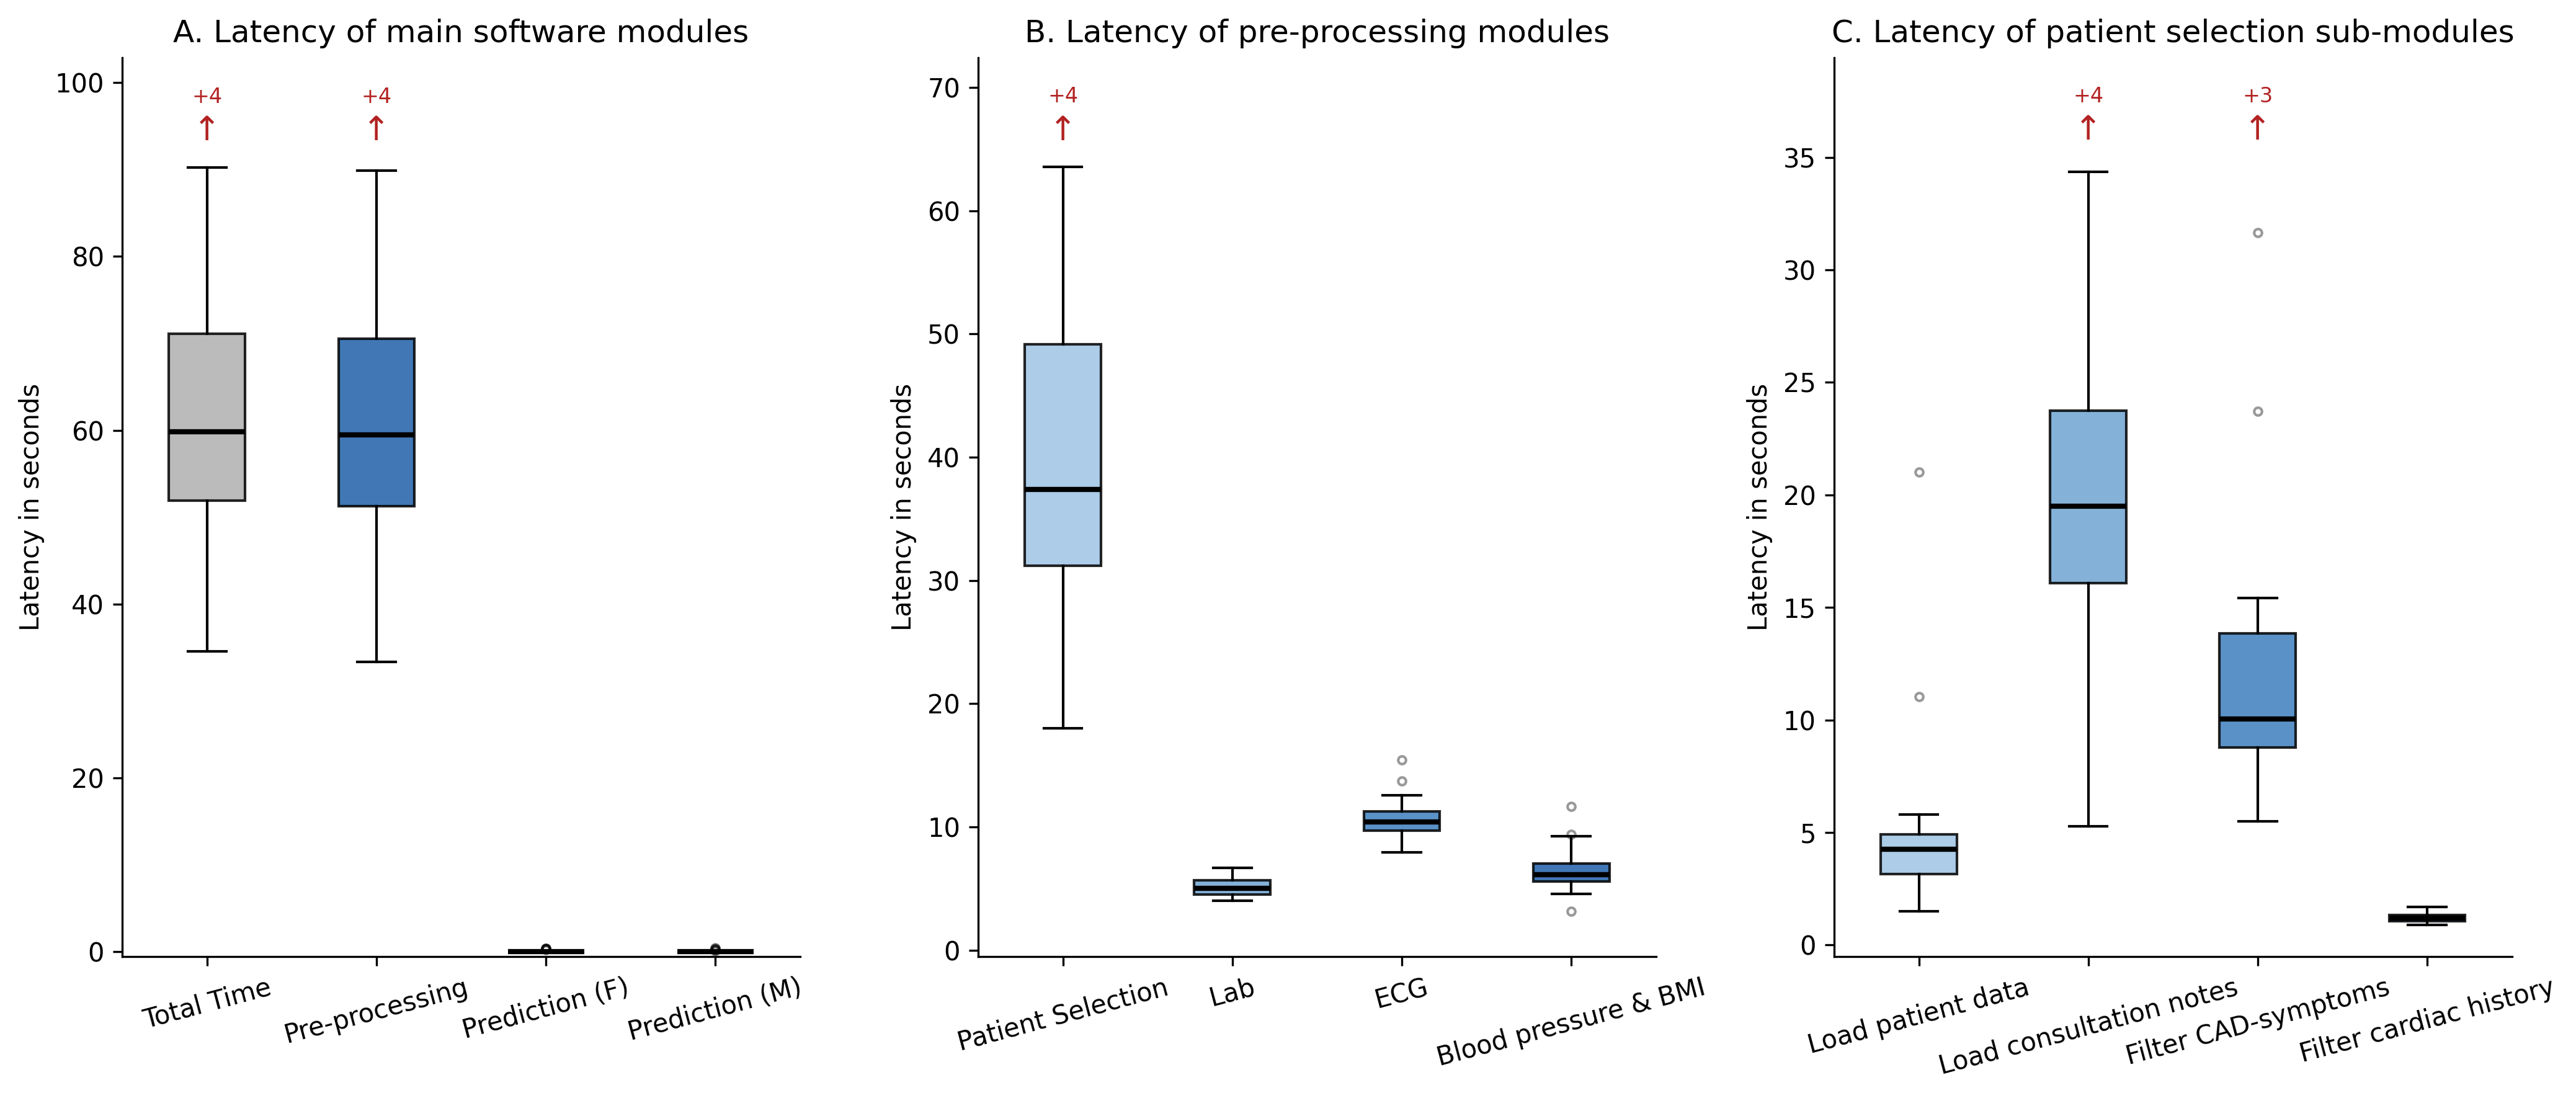

In [29]:
import pandas as pd

cols_A = ["total_time", "total_ETL_time", "prediction_time_female", "prediction_time_male"]
labels_A = ["Total Time", "Pre-processing", "Prediction (F)", "Prediction (M)"]

cols_B = ["main_ETL_patsel_time", "main_Lab_ETL_time", "main_ECG_ETL_time", "main_measurements_ETL_time"]
labels_B = ["Patient Selection", "Lab", "ECG", "Blood pressure & BMI"]

cols_C = ["load_patsel_time", "load_decursus_time", "filter_pob_time", "vg_filter_time"]
labels_C = ["Load patient data", "Load consultation notes", "Filter CAD-symptoms", "Filter cardiac history"]

color_total = "#B0B0B0"  # total_time - neutral
color_ETL_parent = "#1f5fa8"  # total_ETL_time - the "parent" being decomposed
color_pred = "#8FBF8F"  # prediction times - unrelated category

colors_A = [color_total, color_ETL_parent, color_pred, color_pred]
colors_B = ["#9ec4e3", "#6fa4d1", "#3d7fbe", "#1f5fa8"]


def zoom_and_annotate(ax, data_list, upper_pct=95, pad_factor=1.15):
    """
    Set ylim to zoom on the core distribution, and annotate how many
    points are clipped above the visible range for each box.
    """
    # compute a shared upper bound from whisker-ish range (95th pct across all groups)
    upper_bound = max(np.percentile(d, upper_pct) for d in data_list) * pad_factor
    ax.set_ylim(bottom=-0.5, top=upper_bound)

    xticks = ax.get_xticks()
    for x, d in zip(xticks, data_list, strict=False):
        n_clipped = (d > upper_bound).sum()
        if n_clipped > 0:
            ax.annotate(
                "↑", xy=(x, upper_bound * 0.9), ha="center", va="bottom", fontsize=13, color="firebrick", clip_on=False
            )
            ax.annotate(
                f"+{n_clipped}",
                xy=(x, upper_bound * 0.91),
                xytext=(0, 12),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=8,
                color="firebrick",
                clip_on=False,
            )
    return upper_bound


fig, (axA, axB, axC) = plt.subplots(1, 3, figsize=(14, 6), dpi=300)

# Plot A
data_A = [df_patsel_analysis[c].dropna() for c in cols_A]
bpA = axA.boxplot(
    data_A,
    labels=labels_A,
    patch_artist=True,
    medianprops=dict(color="black", linewidth=2),
    flierprops=dict(marker="o", markersize=3, alpha=0.4),
)
for patch, color in zip(bpA["boxes"], colors_A, strict=False):
    patch.set_facecolor(color)
    patch.set_alpha(0.85)

zoom_and_annotate(axA, data_A, upper_pct=85)

axA.set_ylabel("Latency in seconds")
axA.set_title("A. Latency of main software modules")
axA.spines[["top", "right"]].set_visible(False)
axA.tick_params(axis="x", rotation=15)

# Plot B
data_B = [df_patsel_analysis[c].dropna() for c in cols_B]
bpB = axB.boxplot(
    data_B,
    labels=labels_B,
    patch_artist=True,
    medianprops=dict(color="black", linewidth=2),
    flierprops=dict(marker="o", markersize=3, alpha=0.4),
)
for patch, color in zip(bpB["boxes"], colors_B, strict=False):
    patch.set_facecolor(color)
    patch.set_alpha(0.85)

zoom_and_annotate(axB, data_B, upper_pct=85)

axB.set_ylabel("Latency in seconds")
axB.set_title("B. Latency of pre-processing modules")
axB.spines[["top", "right"]].set_visible(False)
axB.tick_params(axis="x", rotation=15)

# Plot C
data_C = [df_patsel_analysis[c].dropna() for c in cols_C]
bpC = axC.boxplot(
    data_C,
    labels=labels_C,
    patch_artist=True,
    medianprops=dict(color="black", linewidth=2),
    flierprops=dict(marker="o", markersize=3, alpha=0.4),
)
for patch, color in zip(bpC["boxes"], colors_B, strict=False):
    patch.set_facecolor(color)
    patch.set_alpha(0.85)

zoom_and_annotate(axC, data_C, upper_pct=85)

axC.set_ylabel("Latency in seconds")
axC.set_title("C. Latency of patient selection sub-modules")
axC.spines[["top", "right"]].set_visible(False)
axC.tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.savefig("output/Supp_Figure_boxplot_latency.png", dpi=300, bbox_inches="tight")
plt.show()

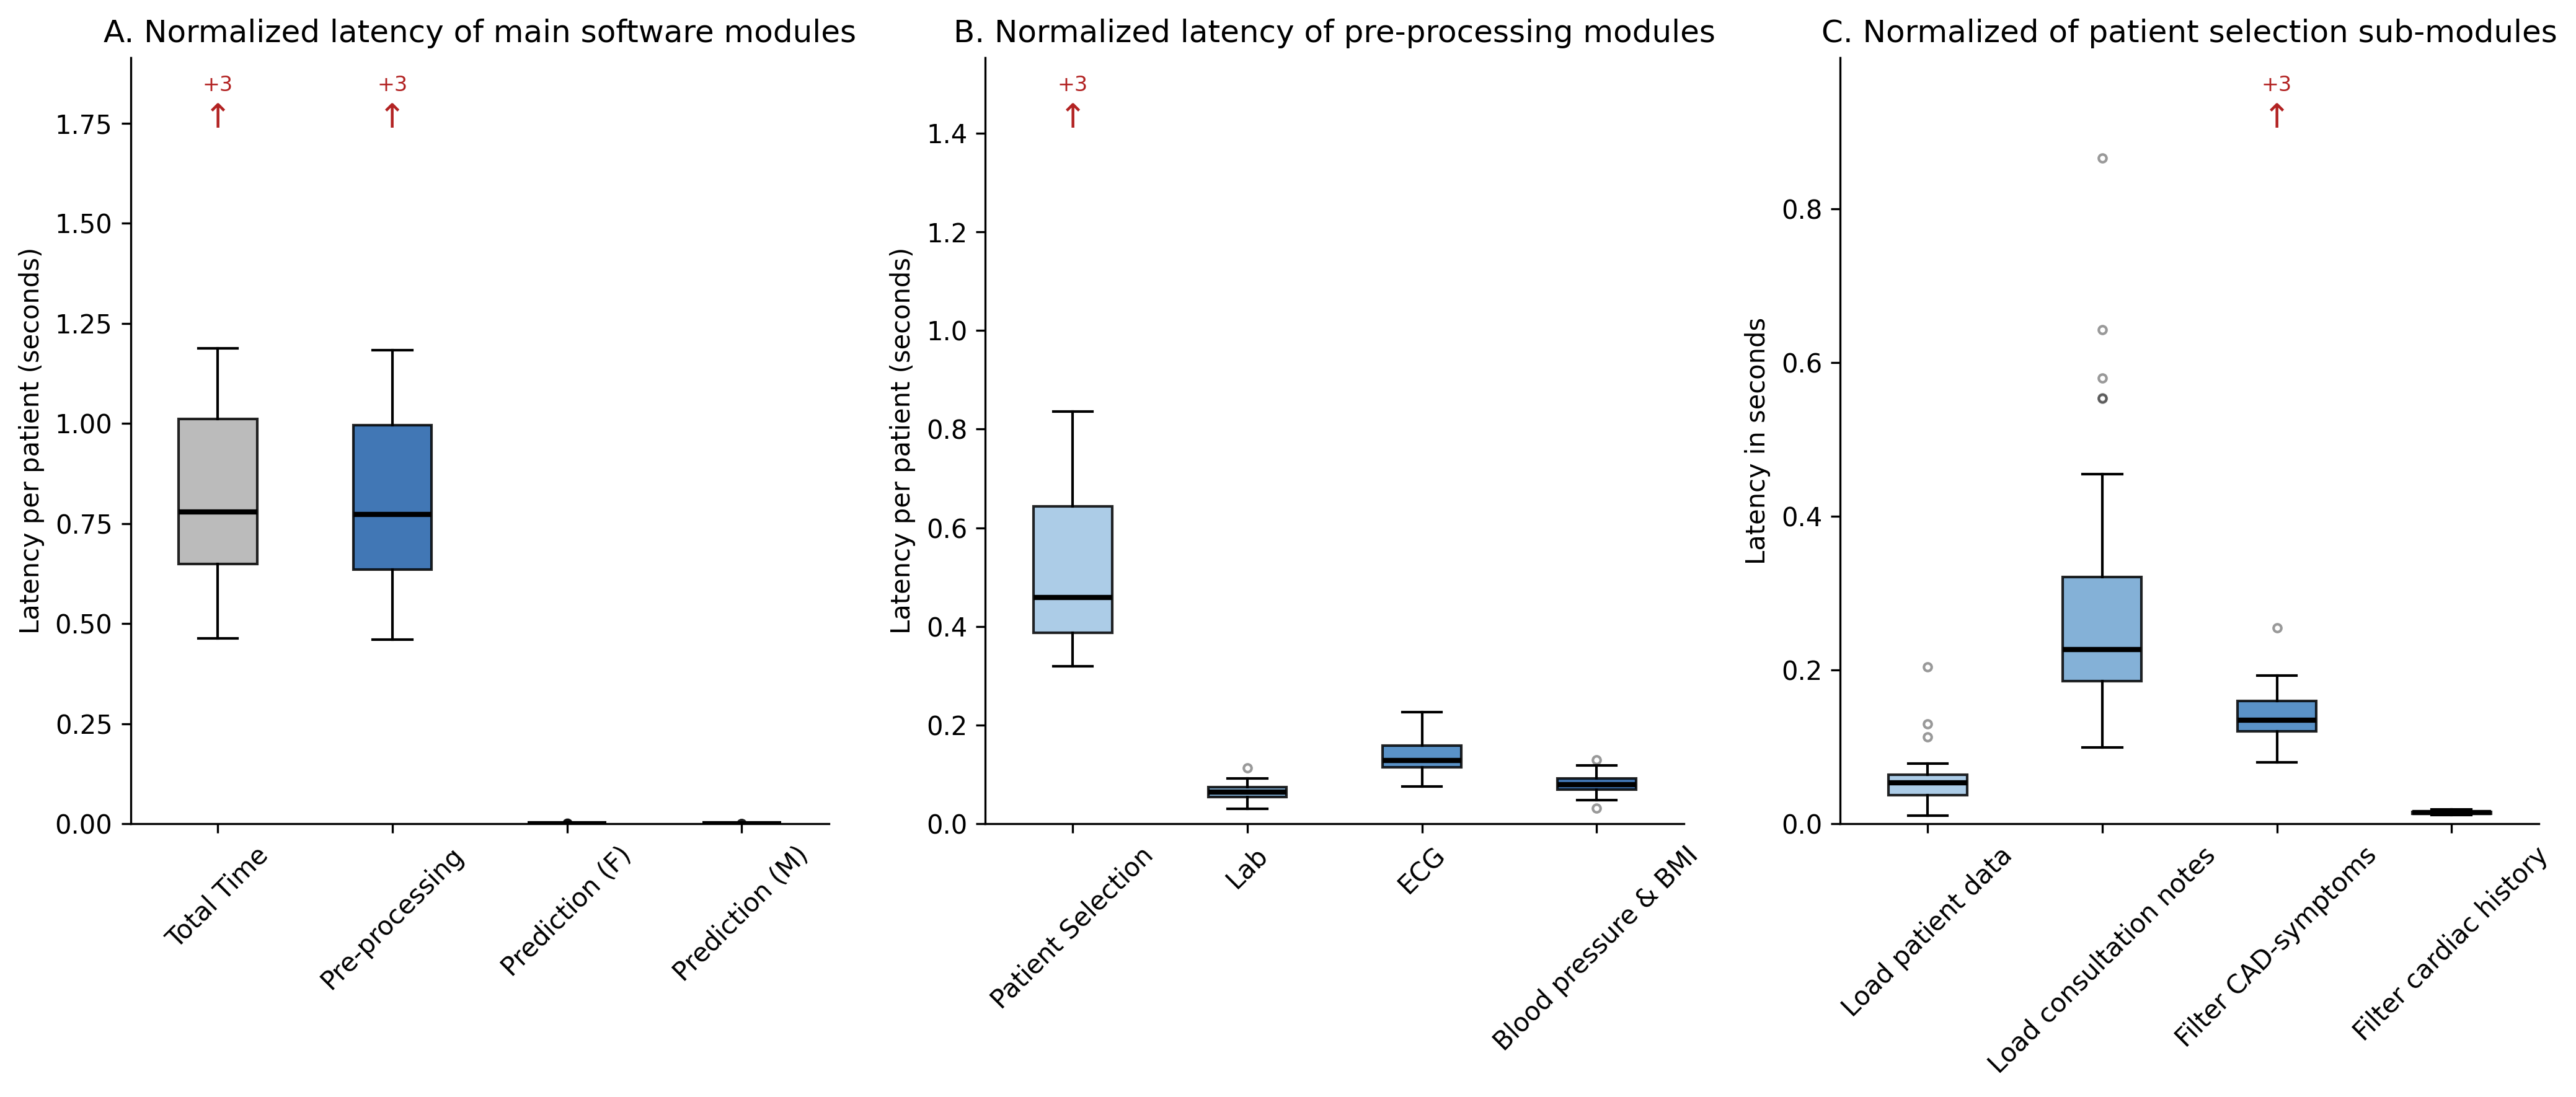

In [30]:
import matplotlib.pyplot as plt
import pandas as pd

cols_A = ["total_time", "total_ETL_time", "prediction_time_female", "prediction_time_male"]
labels_A = ["Total Time", "Pre-processing", "Prediction (F)", "Prediction (M)"]

cols_B = ["main_ETL_patsel_time", "main_Lab_ETL_time", "main_ECG_ETL_time", "main_measurements_ETL_time"]
labels_B = ["Patient Selection", "Lab", "ECG", "Blood pressure & BMI"]

cols_C = ["load_patsel_time", "load_decursus_time", "filter_pob_time", "vg_filter_time"]
labels_C = ["Load patient data", "Load consultation notes", "Filter CAD-symptoms", "Filter cardiac history"]

batch_col = "initial_patsel"

# Normalize: latency per excecution cycle based on batch size
df_norm = df_patsel_analysis.copy()
all_cols = cols_A + cols_B + cols_C
df_norm[all_cols] = df_norm[all_cols].div(df_norm[batch_col], axis=0)

# Overwrite normalized latency for predictions, use only number of predictions instead of full initial batch size
df_norm["prediction_time_female"] = df_norm["prediction_time_female"].div(df_norm["n_female"], axis=0)
df_norm["prediction_time_male"] = df_norm["prediction_time_male"].div(df_norm["n_male"], axis=0)

color_total = "#B0B0B0"
color_ETL_parent = "#1f5fa8"
color_pred = "#8FBF8F"
colors_A = [color_total, color_ETL_parent, color_pred, color_pred]
colors_B = ["#9ec4e3", "#6fa4d1", "#3d7fbe", "#1f5fa8"]


def zoom_and_annotate(ax, data_list, upper_pct=95, pad_factor=1.15):
    """
    Set ylim to zoom on the core distribution, and annotate how many
    points are clipped above the visible range for each box.
    """
    # compute a shared upper bound from whisker-ish range (95th pct across all groups)
    upper_bound = max(np.percentile(d, upper_pct) for d in data_list) * pad_factor
    ax.set_ylim(bottom=0, top=upper_bound)

    xticks = ax.get_xticks()
    for x, d in zip(xticks, data_list, strict=False):
        n_clipped = (d > upper_bound).sum()
        if n_clipped > 0:
            ax.annotate(
                "↑", xy=(x, upper_bound * 0.9), ha="center", va="bottom", fontsize=13, color="firebrick", clip_on=False
            )
            ax.annotate(
                f"+{n_clipped}",
                xy=(x, upper_bound * 0.91),
                xytext=(0, 12),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=8,
                color="firebrick",
                clip_on=False,
            )
    return upper_bound


fig, (axA, axB, axC) = plt.subplots(1, 3, figsize=(14, 6), dpi=300)

# Plot A
data_A = [df_norm[c].dropna() for c in cols_A]
bpA = axA.boxplot(
    data_A,
    labels=labels_A,
    patch_artist=True,
    medianprops=dict(color="black", linewidth=2),
    flierprops=dict(marker="o", markersize=3, alpha=0.4),
)
for patch, color in zip(bpA["boxes"], colors_A, strict=False):
    patch.set_facecolor(color)
    patch.set_alpha(0.85)
zoom_and_annotate(axA, data_A, upper_pct=90)

axA.set_ylabel("Latency per patient (seconds)")
axA.set_title("A. Normalized latency of main software modules")
axA.spines[["top", "right"]].set_visible(False)
axA.tick_params(axis="x", rotation=45)

# Plot B
data_B = [df_norm[c].dropna() for c in cols_B]
bpB = axB.boxplot(
    data_B,
    labels=labels_B,
    patch_artist=True,
    medianprops=dict(color="black", linewidth=2),
    flierprops=dict(marker="o", markersize=3, alpha=0.4),
)
for patch, color in zip(bpB["boxes"], colors_B, strict=False):
    patch.set_facecolor(color)
    patch.set_alpha(0.85)
zoom_and_annotate(axB, data_B, upper_pct=90)

axB.set_ylabel("Latency per patient (seconds)")
axB.set_title("B. Normalized latency of pre-processing modules")
axB.spines[["top", "right"]].set_visible(False)
axB.tick_params(axis="x", rotation=45)

# Plot C
data_C = [df_norm[c].dropna() for c in cols_C]
bpC = axC.boxplot(
    data_C,
    labels=labels_C,
    patch_artist=True,
    medianprops=dict(color="black", linewidth=2),
    flierprops=dict(marker="o", markersize=3, alpha=0.4),
)
for patch, color in zip(bpC["boxes"], colors_B, strict=False):
    patch.set_facecolor(color)
    patch.set_alpha(0.85)

zoom_and_annotate(axC, data_C, upper_pct=90)

axC.set_ylabel("Latency in seconds")
axC.set_title("C. Normalized of patient selection sub-modules")
axC.spines[["top", "right"]].set_visible(False)
axC.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig("output/Fig3_boxplot_latency_normalized.png", dpi=300, bbox_inches="tight")
plt.show()

Compare latency with batch-size

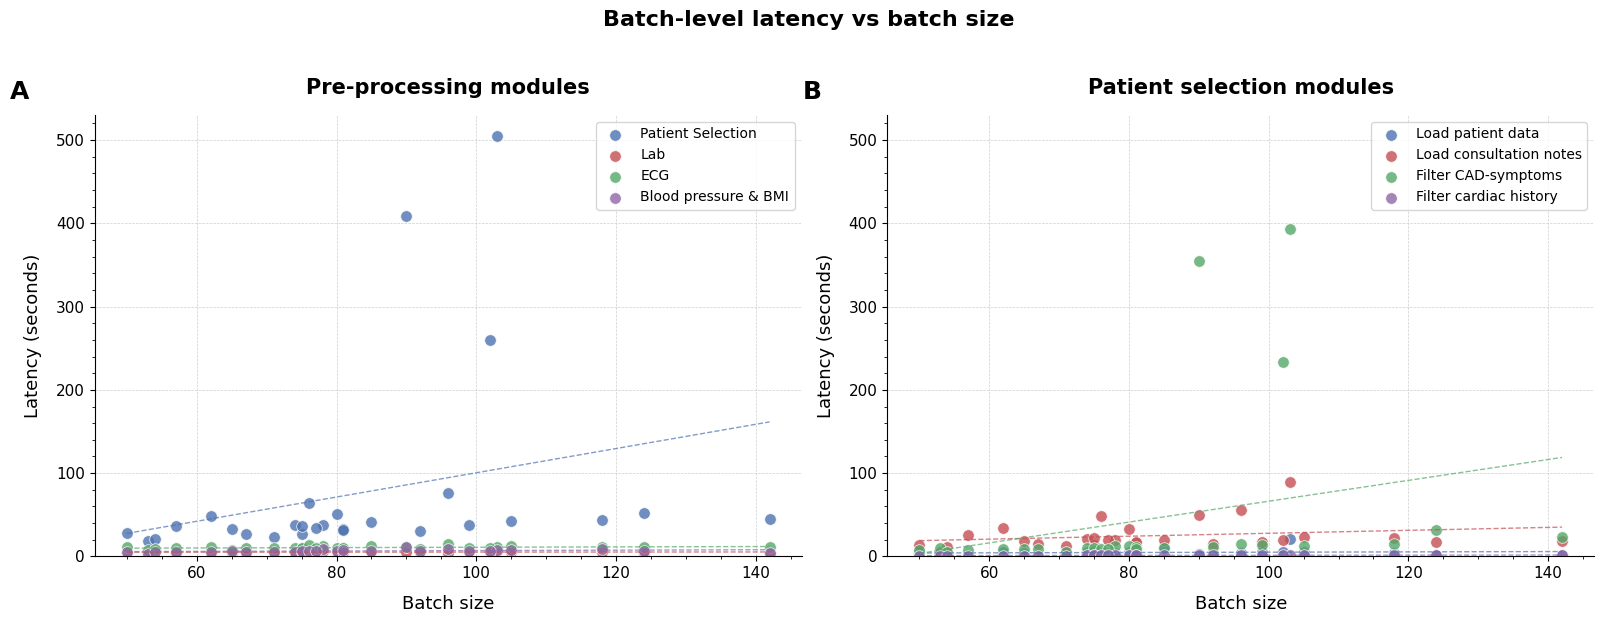

In [31]:
import os

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np

x = df_patsel_analysis["initial_patsel"]

cols_A = ["main_ETL_patsel_time", "main_Lab_ETL_time", "main_ECG_ETL_time", "main_measurements_ETL_time"]
labels_A = ["Patient Selection", "Lab", "ECG", "Blood pressure & BMI"]

cols_B = ["load_patsel_time", "load_decursus_time", "filter_pob_time", "vg_filter_time"]
labels_B = ["Load patient data", "Load consultation notes", "Filter CAD-symptoms", "Filter cardiac history"]

colors = ["#4C72B0", "#C44E52", "#55A868", "#8F66A7"]


def plot_latency_panel(ax, x, df, cols, labels, colors, title):
    for col, label, color in zip(cols, labels, colors):
        y = df[col]

        ax.scatter(x, y, color=color, edgecolors="white", linewidths=0.6,
                   alpha=0.8, s=70, label=label)

        # regression line
        mask = x.notna() & y.notna()
        if mask.sum() >= 2:
            x_valid, y_valid = x[mask], y[mask]
            slope, intercept = np.polyfit(x_valid, y_valid, 1)
            x_line = np.linspace(x_valid.min(), x_valid.max(), 100)
            y_line = slope * x_line + intercept
            ax.plot(x_line, y_line, color=color, linewidth=1, linestyle="--", alpha=0.7)

    ax.set_xlabel("Batch size", fontsize=13, labelpad=10)
    ax.set_ylabel("Latency (seconds)", fontsize=13, labelpad=10)
    ax.set_title(title, fontsize=15, fontweight="bold", pad=15)

    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.6)
    ax.set_axisbelow(True)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

    ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
    ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())
    ax.tick_params(axis="both", which="major", labelsize=11)
    ax.legend(fontsize=10)


fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True)

plot_latency_panel(axes[0], x, df_patsel_analysis, cols_A, labels_A, colors,
                   title="Pre-processing modules")
plot_latency_panel(axes[1], x, df_patsel_analysis, cols_B, labels_B, colors,
                   title="Patient selection modules")

# panel letters
for ax, letter in zip(axes, ["A", "B"]):
    ax.text(-0.12, 1.08, letter, transform=ax.transAxes, fontsize=18, fontweight="bold", va="top")

fig.suptitle("Batch-level latency vs batch size", fontsize=16, fontweight="bold", y=1.03)

y_max = max(ax.get_ylim()[1] for ax in axes)
for ax in axes:
    ax.set_ylim(0, y_max)

plt.tight_layout()
os.makedirs("output", exist_ok=True)
plt.savefig("output/Supp_Figure_Batch-level latency vs batch size.png", dpi=300, bbox_inches="tight")
plt.show()

In [32]:
df_patsel_analysis.loc[df_patsel_analysis["main_ETL_patsel_time"] > 100]

,run_id,created_at,error,initial_patsel,removed_age,remaining_rows,unique_patients,decursus_patients,POB_noVG_patients,Lab_patients,ECG_patients,BMI_patients,BP_patients,n_female,n_male,saved_patients,total_time,total_ETL_time,load_patsel_time,load_decursus_time,filter_pob_time,vg_filter_time,main_ETL_patsel_time,load_lab_time,process_lab_time,process_ecg_time,process_meas_time,load_ECG_classresults,load_ECG_detail,load_BMI_time,load_BP_time,main_measurements_ETL_time,main_ECG_ETL_time,main_Lab_ETL_time,prediction_time_female,prediction_time_male
24,13e25474-568c-42d4-b922-612d428b736b,2026-02-02 14:19:07.577,False,103,2,101,101,97,39,20,31,11,8,14,25,39,532.967,531.72,21.01,89.22,393.44,1.40,505.09,6.59,0.07,0.09,0.03,4.75,6.58,3.90,4.32,8.25,11.42,6.66,0.42,0.28
25,ce26c5c3-a0af-459d-8827-6d142dbd1d7b,2026-01-28 14:17:28.420,False,90,1,89,88,87,37,13,20,7,4,12,25,37,438.333,437.27,2.56,49.85,355.15,1.36,408.94,5.48,0.07,0.09,0.02,5.34,5.41,7.91,3.73,11.66,10.85,5.55,0.41,0.12
26,ad572f03-4168-4de8-b421-1d283339e302,2026-01-23 14:14:47.597,False,102,3,99,99,95,25,8,16,8,4,11,14,25,283.167,281.85,4.96,19.90,234.07,1.20,260.13,4.81,0.07,0.09,0.02,4.86,5.44,3.40,2.73,6.16,10.39,4.88,0.34,0.45


These are the three runs between 23 jan and 7 feb. Very high processing times. 

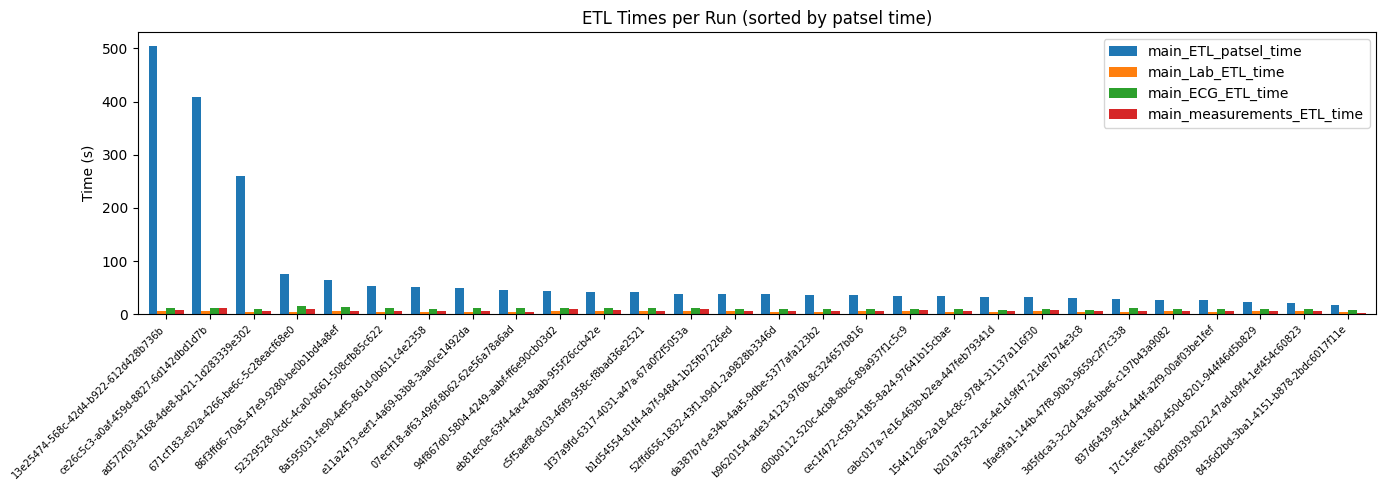

In [33]:
import matplotlib.pyplot as plt
import pandas as pd

time_cols = [
    "main_ETL_patsel_time",
    "main_Lab_ETL_time",
    "main_ECG_ETL_time",
    "main_measurements_ETL_time",
]

# Sort by patsel time so the "high" runs are easy to spot
df_plot = df_patsel_analysis[["run_id"] + time_cols].dropna(subset=time_cols, how="all")
df_plot = df_plot.sort_values("main_ETL_patsel_time", ascending=False).reset_index(drop=True)

# --- Option 1: Grouped bar chart ---
ax = df_plot[time_cols].plot(
    kind="bar",
    figsize=(14, 5),
    width=0.8,
)
ax.set_xticks(range(len(df_plot)))
ax.set_xticklabels(df_plot["run_id"], rotation=45, ha="right", fontsize=7)
ax.set_ylabel("Time (s)")
ax.set_title("ETL Times per Run (sorted by patsel time)")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()